# KMeans lexical path: quality, vectorization constants, and outlier behavior

**Purpose:** notebook 1 established that the k-search's concave/unimodal assumption
genuinely holds for the retained count/categorical path. This notebook answers the two
questions it deferred: how much variance actually needs to be preserved when choosing
`n_components`, and how the pipeline behaves on real cluster content -- visualization,
outlier handling, and a DBSCAN comparison.

Scope: **`tags` + count vectorizer only.** Notebook 1 found TF-IDF + KMeans isn't viable
for free text (`titles`), so there's no reason to quality-test an approach already being
dropped.

- **Containment principle, same as notebook 1:** standalone code in
  `notebooks/diagnostics.py`, not importing `clustering/kmeans.py`/`app.py`.


In [1]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

sys.path.insert(0, ".")
from diagnostics import (
    aggregate_by_user, vectorize, explained_variance_curve,
    cluster_quality_summary, dbscan_eps_sweep,
)

with open("../data/stackoverflow_sample_2021_03_01_n5000.json") as f:
    df_n5000 = pd.DataFrame(json.load(f))

tags = df_n5000["tags"].reset_index(drop=True)
print(f"n5000 tags: {len(tags)} rows")


n5000 tags: 5000 rows


## How much variance does `n_components` actually need to preserve?

Method: hold k fixed and sweep `n_components` finely, tracking both silhouette and the
corresponding cumulative explained variance. Checked at **three different fixed k values**
(50, 82, 120) specifically to confirm the result isn't an artifact of which k happens to
be used -- if the same `n_components` region comes out on top regardless of k, that's a
robust finding, not a coincidence tied to one specific k.


In [2]:
n_components_grid = [10, 15, 20, 25, 30, 35, 40, 50, 75, 100, 150]
k_values_to_check = [50, 82, 120]

quality_results = {}
for k in k_values_to_check:
    rows = []
    for n_comp in n_components_grid:
        vect, counts = vectorize(tags, "count", n_components=n_comp)
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(vect)
        sil = silhouette_score(vect, labels)
        ev = explained_variance_curve(counts, max_components=min(n_comp, counts.shape[0]-1, counts.shape[1]-1), step=max(1, n_comp // 5))
        variance = ev["cumulative_variance"].iloc[-1] if len(ev) else None
        rows.append({"n_components": n_comp, "cumulative_variance": round(float(variance), 3), "silhouette": round(float(sil), 3)})
    quality_results[k] = pd.DataFrame(rows)

quality_results[82]


,n_components,cumulative_variance,silhouette
0,10,0.193,0.673
1,15,0.233,0.664
2,20,0.267,0.720
3,25,0.292,0.736
4,30,0.313,0.762
5,35,0.331,0.728
6,40,0.347,0.693
7,50,0.375,0.631
8,75,0.426,0.518
9,100,0.463,0.443


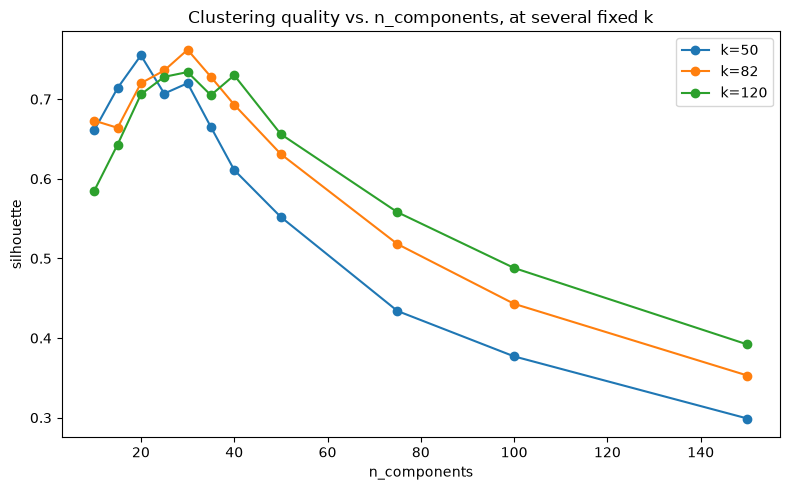

peak n_components per k:
  k=50: peak at n_components=20 (variance=0.267, silhouette=0.755)
  k=82: peak at n_components=30 (variance=0.313, silhouette=0.762)
  k=120: peak at n_components=30 (variance=0.313, silhouette=0.734)


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for k, df_k in quality_results.items():
    ax.plot(df_k["n_components"], df_k["silhouette"], marker="o", label=f"k={k}")
ax.set_xlabel("n_components")
ax.set_ylabel("silhouette")
ax.set_title("Clustering quality vs. n_components, at several fixed k")
ax.legend()
fig.tight_layout()
plt.show()

print("peak n_components per k:")
for k, df_k in quality_results.items():
    best_row = df_k.loc[df_k["silhouette"].idxmax()]
    print(f"  k={k}: peak at n_components={int(best_row['n_components'])} "
          f"(variance={best_row['cumulative_variance']}, silhouette={best_row['silhouette']})")


### Observations

**`n_components` clearly and substantially affects clustering quality** -- at k=82,
silhouette ranges from 0.762 (n_components=30) down to 0.353 (n_components=150), more
than a 2x spread. This is a real, large effect, not a minor tuning detail.

**The quality peak is robust across k, not an artifact of one specific choice.** All
three tested k values (50, 82, 120) peak in the same n_components≈20-30 region,
corresponding to roughly **0.27-0.31 cumulative variance**.

This is specific to this dataset's characteristics (vocabulary size, tag co-occurrence
structure); it's a well-evidenced starting point for this pipeline, not a universal
constant -- worth re-checking if the vectorization pipeline is later applied to
meaningfully different categorical data.


## Cluster visualization

A 2D projection (a separate 2-component SVD, used only for plotting -- not the same
reduction used for clustering) of a representative clustering (`n_components=30, k=82`),
colored by cluster assignment.


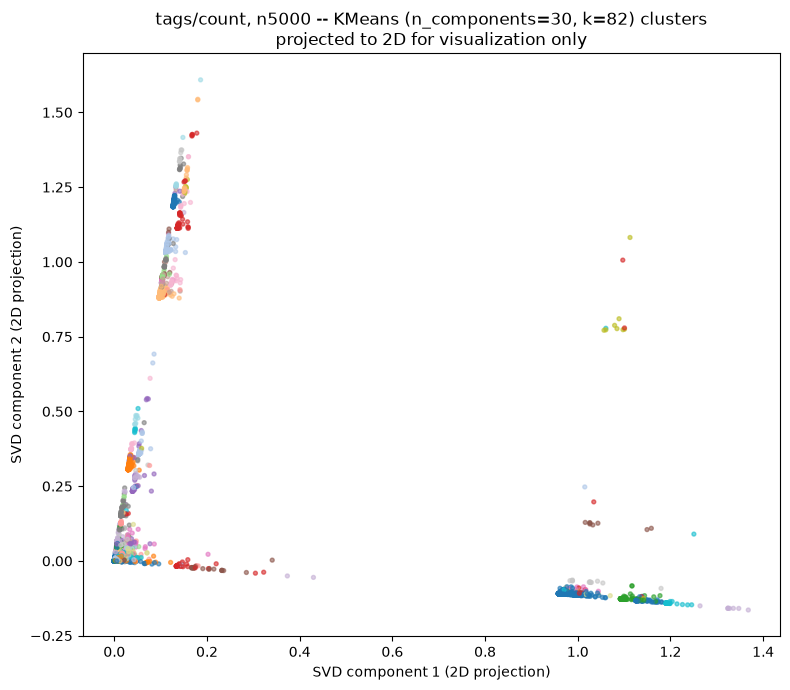

In [4]:
vect_2d, _ = vectorize(tags, "count", n_components=2)
vect_30, _ = vectorize(tags, "count", n_components=30)
labels_30 = KMeans(n_clusters=82, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(vect_30)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(vect_2d[:, 0], vect_2d[:, 1], c=labels_30, cmap="tab20", s=8, alpha=0.6)
ax.set_title("tags/count, n5000 -- KMeans (n_components=30, k=82) clusters\nprojected to 2D for visualization only")
ax.set_xlabel("SVD component 1 (2D projection)")
ax.set_ylabel("SVD component 2 (2D projection)")
fig.tight_layout()
plt.show()


In [5]:
# What drives the sharp straight edges visible in the plot above? Distance from origin
# alone can't tell rays apart from a single blob -- check the angular distribution too.
dist_from_origin = np.linalg.norm(vect_2d, axis=1)
theta = np.degrees(np.arctan2(vect_2d[:, 1], vect_2d[:, 0]))
n_tags = tags.map(len)

print("correlation between distance-from-origin and number of tags:", round(float(np.corrcoef(dist_from_origin, n_tags)[0, 1]), 3))
print()

far_mask = dist_from_origin > np.percentile(dist_from_origin, 75)
ray1 = far_mask & (theta > -15) & (theta < 5)
ray2 = far_mask & (theta > 75) & (theta < 95)
off_ray = far_mask & ~ray1 & ~ray2
print(f"far points: {far_mask.sum()}  |  ray1 (~-10 to 0 deg): {ray1.sum()}  |  ray2 (~80 to 90 deg): {ray2.sum()}  |  off-ray: {off_ray.sum()}")
print()

print("ray1 sample:")
for t in tags[ray1].sample(4, random_state=1):
    print(" ", t)
print("ray2 sample:")
for t in tags[ray2].sample(4, random_state=1):
    print(" ", t)
print("off-ray sample (between the two rays):")
for t in tags[off_ray].sample(4, random_state=1):
    print(" ", t)


correlation between distance-from-origin and number of tags: 0.175

far points: 1250  |  ray1 (~-10 to 0 deg): 766  |  ray2 (~80 to 90 deg): 463  |  off-ray: 21

ray1 sample:
  ['python', 'opencv', 'canny-operator']
  ['python', 'loops', 'or-tools', 'vehicle-routing']
  ['python', 'opencv', 'draw']
  ['python', 'dataframe', 'loops', 'if-statement', 'optimization']
ray2 sample:
  ['javascript', 'node.js', 'json', 'express', 'json.net']
  ['javascript', 'reactjs']
  ['javascript', 'reactjs', 'mongodb', 'mern']
  ['javascript', 'node.js']
off-ray sample (between the two rays):
  ['python', 'html', 'beautifulsoup', 'python-requests', 'find']
  ['python', 'html', 'flask', 'flask-sqlalchemy']
  ['javascript', 'python', 'json', 'parsing']
  ['javascript', 'python', 'django', 'django-templates', 'javascript-objects']


### Observations

The sharp, distinct edges in the scatter are **a real data property expressed through a
side effect of the projection method, not noise.** `CountVectorizer` output is
non-negative, and `TruncatedSVD` doesn't center the data -- so its top two components end
up aligned with the two single most frequent topics in the vocabulary, not an even
representation of all terms. Checking the angular distribution (not just distance from
origin, which can't distinguish separate rays from a single blob) confirms there are
genuinely **two** dominant rays, not one amorphous edge: one (766 of the far points)
dominated by `python`-tagged posts, the other (463 points) dominated by
`javascript`-tagged posts -- the two axes are essentially "python-ness" and
"javascript-ness".

The small number of points that fall **between** the two rays (21 of 1250 far points)
aren't noise either -- they're overwhelmingly posts tagged with *both* python and
javascript/html together (e.g. `[javascript, python, flutter, dart, ...]`,
`[python, html, css, scrapy]`), landing at an intermediate angle proportional to how much
of each topic's signal the post carries. That's exactly what you'd expect geometrically
from a vector that's a genuine mix of both basis directions.

So the edges reflect real, specific dominant topics in the data (not just "frequent tags"
in general), and the much larger, more varied remainder of posts compresses toward the
origin because their signal lives in directions these first 2 components don't capture --
a consequence of using only 2 components for visualization specifically. That compression
doesn't happen in the actual 30-dimensional clustering space, where those less-frequent
patterns have room to spread out and form their own clusters (as the per-cluster content
already showed: java, c#, r, etc. all separate cleanly alongside python and javascript).
The 2D view is more useful for spotting the few most dominant topics than for judging the
overall cluster structure, which genuinely lives in higher dimensions than 2.

## Outlier behavior: cluster-level and point-level

Using the established `n_components=30, k=82` configuration.


In [6]:
quality = cluster_quality_summary(vect_30, labels_30)
print(f"n_clusters={len(quality)}, singleton clusters={(quality['size']==1).sum()}, "
      f"size<=3 clusters={(quality['size']<=3).sum()}, "
      f"negative-silhouette clusters={(quality['mean_silhouette']<0).sum()}")
print()
print("weakest clusters by mean silhouette:")
print(quality.head(6).to_string(index=False))


n_clusters=82, singleton clusters=0, size<=3 clusters=2, negative-silhouette clusters=0

weakest clusters by mean silhouette:
 cluster  size  mean_silhouette
       3     3            0.055
      51    26            0.063
      47    33            0.121
      65     8            0.155
      58    19            0.188
      55    10            0.225


**No genuine junk clusters.** Zero singletons, zero negative-silhouette clusters. The
weakest clusters by mean silhouette are coherent, just organized around a cross-cutting
secondary tag (e.g. "arrays") that spans many primary languages, which makes them
inherently more diffuse without being topically meaningless.

A per-cluster average can still hide individual problem points, though -- a cluster can
have a fine *mean* silhouette while containing a few points that are a poor fit for it.
Checking statistically, at the individual-point level:


In [7]:
# per-point distance to own cluster centroid, then a z-score within that cluster's own
# distribution -- a direct statistical outlier measure, not just an eyeballed one.
distances = np.zeros(len(labels_30))
for label in np.unique(labels_30):
    mask = labels_30 == label
    centroid = vect_30[mask].mean(axis=0)
    distances[mask] = np.linalg.norm(vect_30[mask] - centroid, axis=1)

z_scores = np.zeros(len(labels_30))
for label in np.unique(labels_30):
    mask = labels_30 == label
    d = distances[mask]
    if d.std() > 0:
        z_scores[mask] = (d - d.mean()) / d.std()

for thresh in [2, 2.5, 3]:
    n_outliers = int((z_scores > thresh).sum())
    print(f"z-score > {thresh}: {n_outliers} points ({100*n_outliers/len(labels_30):.1f}%)")

print()
print("sample of points with z-score > 3 (statistical outliers within their own cluster):")
for i in np.where(z_scores > 3)[0][:8]:
    print(f"  cluster={labels_30[i]}, z={z_scores[i]:.2f}, tags={tags[i]}")


z-score > 2: 288 points (5.8%)
z-score > 2.5: 201 points (4.0%)
z-score > 3: 134 points (2.7%)

sample of points with z-score > 3 (statistical outliers within their own cluster):
  cluster=0, z=3.03, tags=['firebase', 'google-cloud-firestore']
  cluster=16, z=5.90, tags=['javascript', 'android', 'react-native', 'expo']
  cluster=17, z=3.26, tags=['php', 'jquery']
  cluster=8, z=5.01, tags=['c#', 'asp.net', 'reactjs', 'controller', 'graphql']
  cluster=13, z=3.94, tags=['c++', 'arrays']
  cluster=17, z=3.69, tags=['php', 'json', 'wordpress', 'arraylist']
  cluster=16, z=4.08, tags=['javascript', 'c#', 'events', 'cefsharp']
  cluster=73, z=4.32, tags=['javascript', 'python', 'flutter', 'dart', 'flutter-layout']


### Observations

**There's no cluster-level outlier problem, but there is a real, measurable point-level
one.** About 2.7% of points (z>3) are statistical outliers within whatever cluster they
were assigned to -- a meaningfully worse fit than their clustermates, even though the
cluster's average silhouette looks fine. This is exactly the failure mode a per-cluster
average can't surface.

**This converges with the DBSCAN comparison below, not coincidentally.** Several of these
same statistical outliers (`[javascript, android, react-native, expo]`,
`[c#, asp.net, reactjs, controller, graphql]`) are also flagged as DBSCAN noise points.
Two independent methods -- one density-based, one a simple within-cluster z-score --
agreeing on the same points is much stronger evidence than either alone that these are
genuinely cross-cutting, hard-to-place posts, not an artifact of either method.


## DBSCAN: a quick comparison, and a tuning-efficiency argument

The motivating question from early on: does KMeans's lack of a "noise" class actually
cost anything in practice, and separately -- for an app that has to pick parameters
automatically with no human eyeballing a plot -- which approach is actually easier to
tune well?


In [8]:
print("=== eps sweep, min_samples=3 ===")
eps_sweep = dbscan_eps_sweep(vect_30, eps_values=[0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0], min_samples=3)
print(eps_sweep.to_string(index=False))
print()
print("=== min_samples sensitivity at eps=0.6 ===")
for ms in [2, 3, 5, 8]:
    labels_db = DBSCAN(eps=0.6, min_samples=ms).fit_predict(vect_30)
    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    noise = np.mean(labels_db == -1)
    print(f"  min_samples={ms}: n_clusters={n_clusters}, noise_fraction={noise:.3f}")


=== eps sweep, min_samples=3 ===


 eps  n_clusters  noise_fraction
0.50         101           0.040
0.55          97           0.040
0.60          95           0.038
0.65          89           0.037
0.70          86           0.036
0.75          78           0.036
0.80          71           0.035
0.85          54           0.032
0.90          39           0.029
0.95          16           0.018
1.00           1           0.003

=== min_samples sensitivity at eps=0.6 ===
  min_samples=2: n_clusters=130, noise_fraction=0.024
  min_samples=3: n_clusters=95, noise_fraction=0.038
  min_samples=5: n_clusters=70, noise_fraction=0.056


  min_samples=8: n_clusters=51, noise_fraction=0.078


In [9]:
labels_dbscan = DBSCAN(eps=0.7, min_samples=3).fit_predict(vect_30)
noise_mask = labels_dbscan == -1
print(f"noise points at eps=0.7: {noise_mask.sum()} ({100*noise_mask.mean():.1f}%)")
print("sample of noise-labeled tag lists:")
for t in tags[noise_mask].head(8):
    print(" ", t)


noise points at eps=0.7: 182 (3.6%)
sample of noise-labeled tag lists:
  ['javascript', 'android', 'react-native', 'expo']
  ['php', 'jquery']
  ['angular', 'typescript', 'amazon-web-services', 'aws-parameter-store', 'aws-config']
  ['c#', 'asp.net', 'reactjs', 'controller', 'graphql']
  ['c++', 'arrays']
  ['java', 'html', 'spring', 'spring-mvc', 'url']
  ['c#', 'php', 'html']
  ['mysql', 'sql', 'json', 'group-by', 'distinct']


### Observations

**DBSCAN's cluster count degrades gradually, not catastrophically** -- 101 clusters at
eps=0.5 down to 16 at eps=0.95, collapsing to a single cluster only right at eps=1.0.
There's a usable range (roughly 0.6-0.8) giving a cluster count comparable to KMeans's
k=82, with a stable ~3.5-4% noise fraction. `min_samples` has a real, independent effect
too (130 clusters at min_samples=2 down to 51 at min_samples=8, at the same eps) --
**DBSCAN's parameter space is genuinely two-dimensional**, not one.

**The noise points are real, not arbitrary.** They're overwhelmingly cross-cutting,
multi-topic posts, matching the statistical-outlier findings above -- a genuine,
demonstrated capability KMeans lacks.

**On tuning efficiency specifically -- KMeans is clearly the better fit for an app that
has to pick parameters automatically, with no human in the loop.** KMeans has one
parameter (k), and both notebooks together establish that its score-vs-k landscape is
close to concave for this data -- a well-behaved, 1-dimensional search space with a
principled, computable objective (silhouette) to automate against, which is exactly what
the current heuristic search already exploits. DBSCAN requires tuning **two**
interacting parameters (`eps` and `min_samples`), and there isn't an equally clean,
automatable objective for picking them -- the standard approach (a k-distance "elbow"
plot) is inherently more manual/visual than maximizing a score, and this notebook's own
eps sweep only found a usable range by trying many values and eyeballing the result, not
by optimizing a clear automatic signal the way `_search_kmeans_k` does for KMeans. For a
pipeline that needs to run unattended on arbitrary user-uploaded data, that's a real,
practical argument for keeping KMeans as the default, independent of the
quality-comparison findings above.


## Conclusions for `clustering/kmeans.py` (input to phase 2)

1. **Set the variance target closer to 0.3.** This is now
   numerically justified, not deferred: the quality peak is robust across three different
   fixed k values, all landing in the same n_components≈20-30 (variance≈0.27-0.31) region.
   The SVD component search still needs the explicit "target not reached" fallback
   flagged in notebook 1, but the target itself should also change, not just gain a
   fallback.

2. **No cluster-level outlier problem, but a real, measurable point-level one (~2.7% of
   points, statistically).** Worth considering surfacing this as a per-point diagnostic in
   the app (e.g. flagging high-z-score points within their assigned cluster) rather than
   only showing per-cluster silhouette and distance-to-centroid as it does today.

3. **Keep KMeans as the default; DBSCAN stays a documented, optional alternative.** Its
   noise-detection is a real, demonstrated capability gap (confirmed by convergence with
   the independent statistical-outlier check), but KMeans's single well-behaved parameter
   is a genuinely better fit for a pipeline that has to tune itself automatically on
   arbitrary data, independent of the quality comparison.
